In [25]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
import seaborn as sns
import numpy as np
from sklearn.cluster import DBSCAN


df = pd.read_csv("data_grupp_3.csv")

df.info()
print(df.shape)

df.head(10)

<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   alder_ar             240 non-null    float64
 1   vilopuls_bpm         240 non-null    float64
 2   blodtryck_sys_mmhg   240 non-null    float64
 3   kolesterol_ldl_mmol  240 non-null    float64
 4   traning_tim_vecka    240 non-null    float64
 5   bmi                  240 non-null    float64
 6   target               240 non-null    str    
dtypes: float64(6), str(1)
memory usage: 13.3 KB
(240, 7)


,alder_ar,vilopuls_bpm,blodtryck_sys_mmhg,kolesterol_ldl_mmol,traning_tim_vecka,bmi,target
0,39.6,66.0,107.0,2.13,2.9,22.1,Lag_risk
1,57.9,94.0,156.0,4.26,2.4,30.6,Hog_risk
2,45.7,68.0,136.0,3.13,5.3,24.8,Lag_risk
3,48.7,51.0,97.0,2.69,5.1,31.8,Lag_risk
4,44.1,57.0,106.0,3.56,4.7,23.8,Lag_risk
5,49.0,66.0,110.0,1.59,4.5,23.4,Lag_risk
6,42.2,91.0,131.0,3.38,0.0,24.5,Forhojd_risk
7,51.5,77.0,119.0,2.07,0.0,26.8,Forhojd_risk
8,66.2,107.0,168.0,5.27,0.0,31.6,Hog_risk
9,46.6,83.0,130.0,4.82,0.0,20.1,Forhojd_risk


In [18]:
df["target"].value_counts()

target
Lag_risk        80
Hog_risk        80
Forhojd_risk    80
Name: count, dtype: int64

In [19]:
df.describe()

,alder_ar,vilopuls_bpm,blodtryck_sys_mmhg,kolesterol_ldl_mmol,traning_tim_vecka,bmi
count,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000
mean,52.459167,73.720833,138.995833,3.781000,2.810000,27.774583
std,15.974700,15.581651,26.934990,1.460038,2.543953,5.096736
min,20.000000,42.000000,90.000000,1.200000,0.000000,17.500000
25%,41.500000,63.000000,119.000000,2.720000,0.200000,23.775000
50%,51.450000,74.000000,136.000000,3.795000,2.600000,28.150000
75%,63.550000,84.000000,158.250000,4.932500,4.500000,31.500000
max,88.000000,114.000000,200.000000,7.500000,14.000000,42.000000


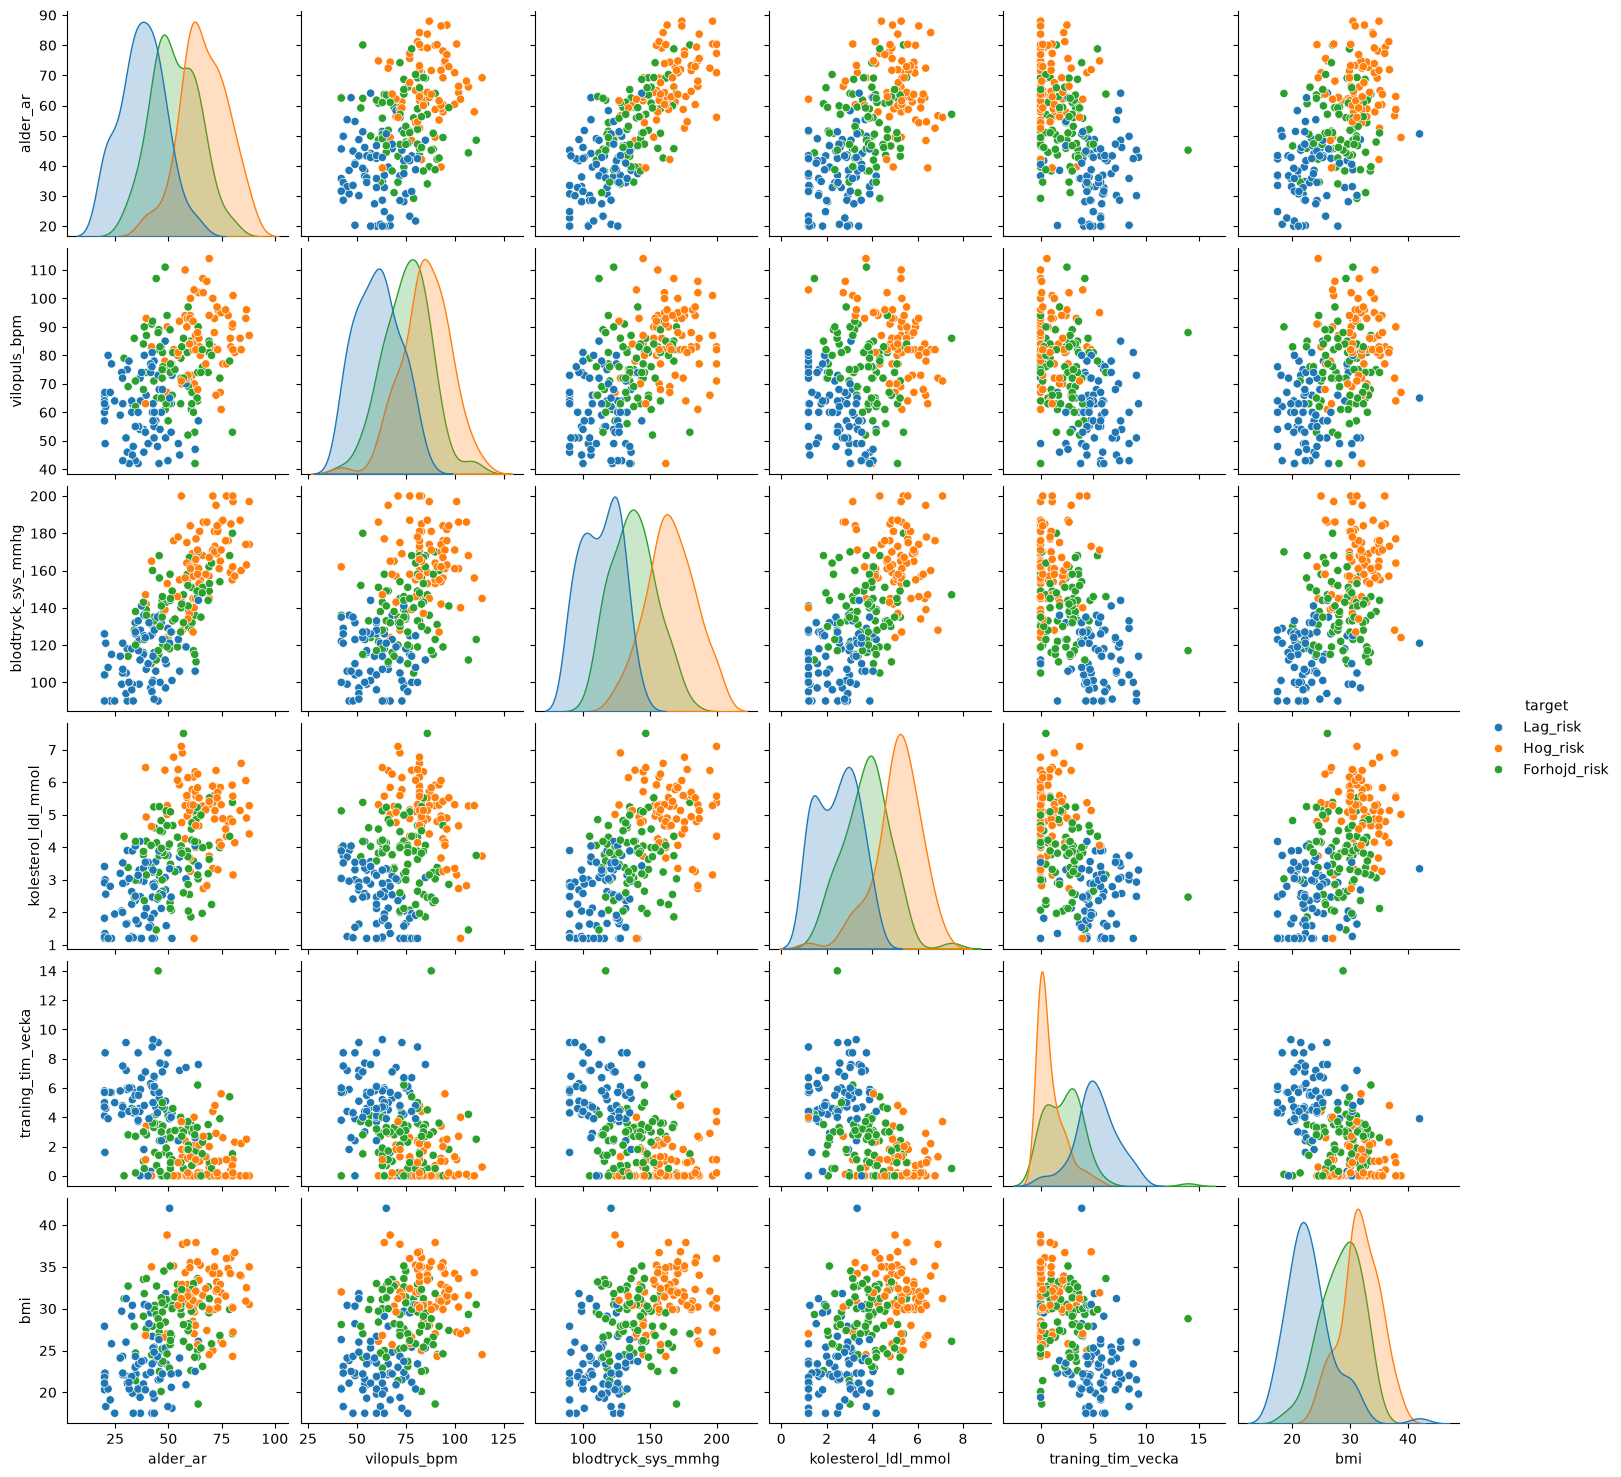

In [20]:
sns.pairplot(df, hue="target")
plt.show()

A1 - Förbehandling och skalning

In [22]:
X = df.drop(columns=["target"])
y = df["target"]
print(X.shape, y.shape)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled.mean(axis=0).round(2))
print(X_scaled.std(axis=0).round(2))


(240, 6) (240,)
[-0.  0. -0. -0. -0. -0.]
[1. 1. 1. 1. 1. 1.]


A2 - Unsupervised screening 

In [23]:
kmeans = KMeans(random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)
print(pd.Series(kmeans_labels).value_counts().sort_index())

0    26
1    44
2    33
3    32
4    33
5    17
6    32
7    23
Name: count, dtype: int64


In [26]:
dbscan = DBSCAN()
dbscan_labels = dbscan.fit_predict(X_scaled)
print(pd.Series(dbscan_labels).value_counts().sort_index())

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
noise_pct = (dbscan_labels == -1).mean() * 100
print(f"Antal kluster: {n_clusters}, andel brus: {noise_pct:.1f} %")

-1    240
Name: count, dtype: int64
Antal kluster: 0, andel brus: 100.0 %
